In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap
import geopandas as gpd
import snowflake.connector
import getpass
from os import getlogin

In [27]:
current_fuel_data = r"\\sce.eix.com\workgroup\SPE_DSA\Charles\ADS_forecast\Dist Circuit FPI2 Forecast_05-18-2026.csv"
forecast_fuel = pd.read_csv(current_fuel_data)
# for the forecast data, make Circuit the first part of _ separated by "_"
forecast_fuel['Circuit'] = forecast_fuel['Circuit'].apply(lambda x: x.split('_')[0])
# make sure Date is date string of Datetime
forecast_fuel['Date'] = pd.to_datetime(forecast_fuel['Datetime']).dt.strftime('%Y-%m-%d')

Get a sense of HDF breakdown (i.e. how close/far from 0.85 we are)

In [28]:
# for forecast data, groupby Date, Circuit, take the mean of FuelsIndex_max_FPI2
dist_df_forecast_agg = forecast_fuel.groupby(['Date', 'Circuit'])['FuelsIndex_max_FPI2'].mean().reset_index()

In [29]:
# for Date 2026-05-18, get the top 10 circuits with highest FuelsIndex_max_FPI2
top10_circuits = dist_df_forecast_agg[dist_df_forecast_agg['Date'] == '2026-05-18'].nlargest(10, 'FuelsIndex_max_FPI2')
# rename FuelsIndex_max_FPI2 to Fuel Reading
top10_circuits = top10_circuits.rename(columns={'FuelsIndex_max_FPI2': 'Fuel Reading'})
top10_circuits

,Date,Circuit,Fuel Reading
61,2026-05-18,BANDAGE,0.83125
176,2026-05-18,CARRIAGE,0.82750
1029,2026-05-18,TUNGSTEN,0.82500
691,2026-05-18,ONAGA,0.76250
132,2026-05-18,BURKETT,0.74250
483,2026-05-18,INYO LUMBER,0.74250
344,2026-05-18,FAYE,0.73875
267,2026-05-18,CROSSLEY,0.73375
462,2026-05-18,HOWITZER,0.73375
65,2026-05-18,BATTALION,0.71875


In [30]:
dist_df_forecast_agg[dist_df_forecast_agg['Circuit']=='BIRCHIM']

,Date,Circuit,FuelsIndex_max_FPI2
88,2026-05-18,BIRCHIM,0.588472
1191,2026-05-19,BIRCHIM,0.561528
2294,2026-05-20,BIRCHIM,0.564861
3397,2026-05-21,BIRCHIM,0.568611
4500,2026-05-22,BIRCHIM,0.582500
5603,2026-05-23,BIRCHIM,0.611111
6706,2026-05-24,BIRCHIM,0.635556
7809,2026-05-25,BIRCHIM,0.635556


### Connecting to Snowflake

In [31]:
def snowflake_conn(user, settings):
    '''
    Set up a connection to Snowflake DB.
    '''    
    cnn = snowflake.connector.connect(
        user=user,
        authenticator='externalbrowser',
        account='edwsce',
        region='west-us-2.azure',
        warehouse=settings['warehouse'],
        role=settings['role'], 
        database=settings['database'],
        schema=settings['schema'])
    
    return cnn

In [32]:
def get_snowflake_data_single_query(user, settings, sql):
    '''
    After setting a connection to a Snowflake table, query the data.
    It queries a single sql.
    '''
   
    conn = snowflake_conn(user, settings) 
    cur=conn.cursor()

    # Query the data     
    cur.execute(sql)
    pandas_df = cur.fetch_pandas_all()

    conn.close()

    return pandas_df

In [33]:
# Snowflake connection setting
snowflake_config = {
    'role':'TONGCJ_PROD_ROLE',
    'warehouse':'PROD_TD_SS_ASP_DSAA_CNSMPADHOCWH2',    # 'PROD_TD_SS_ASP_DSAA_CNSMPADHOCWH2' is anotherwarehouse
    'database':'PROD_TD_SS',
    'schema':'TD_ASP_DSAA_SS'
}

uid = getlogin()

sql_query = '''SELECT * FROM RPT_IGS_FPI_DE WHERE YEAR = 2026'''

In [34]:
fuel_data_ytd = get_snowflake_data_single_query(uid, snowflake_config, sql_query)

 pip install snowflake-connector-python[secure-local-storage]


Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...
Going to open: https://eix.okta.com/app/snowflake/exkonbplq1Q9t5zld0x7/sso/saml?SAMLRequest=nZLBctowEIZfxaOeLdmmhFqDyVAILR2SmgDJNDfFFkRFloxWxk6evrIJnfSQHHrzyN%2BuPu2%2Fw8umkN6RGxBaJSjEAfK4ynQu1C5Bm%2FXM%2F4I8sEzlTGrFE%2FTMAV2OhsAKWdJxZZ%2FULT9UHKznGimg3Y8EVUZRzUAAVazgQG1GV%2BPrBY1wQEujrc60RG9KPq5gANxYZ3guyUE4vSdrS0pIXde47mFtdiQKgoAEMXFUi3w684170zt8SILPLe8Ih6evbl%2BFOo3gI63HEwT0%2B3qd%2BunP1Rp547PqRCuoCm5W3BxFxje3i5MAOIOr6f1qcoVrNza%2FAj%2FC7KUyHIPS9VayPc90UVbWtcbui2x5TqTeCff6%2BTRB5V7ku634wWZZxZaDb4dF%2BHB3wTb3%2BzRiC6v6x7Jufmfp%2BHAofi2vM%2BTdneON2njnABWfqzZU646C6MIP%2Bn4Yr8MejWLaG%2BBB3HtA3tTZCcVsV3k256LBem9ZJ8bKkvx1JrzZa%2FVYykO4jG3%2FReZBMyAAmrT5otPK0O5yM%2FqvQQzJ2xavK3jjUplPUy1F9uzNtCmYfT%2B0EIfdicj9bYdSXjAhx3luOIALT0pdTwxn1m26NRVHZHS69d9dH%2F0B&Relay

 pip install snowflake-connector-python[secure-local-storage]


In [41]:
# get the month value from DATE
fuel_data_ytd['MONTH'] = pd.to_datetime(fuel_data_ytd['DATE']).dt.month
# categorize FUEL_INDEX into 4 categories, 0-0.5, 0.5-0.75, 0.75-0.85, 0.85+
def categorize_fuel_index(fuel_index):
    if fuel_index < 0.5:
        return '0-0.5'
    elif fuel_index < 0.75:
        return '0.5-0.75'
    elif fuel_index < 0.85:
        return '0.75-0.85'
    else:
        return '0.85+'
fuel_data_ytd['FUEL_INDEX_CATEGORY'] = fuel_data_ytd['FUEL_INDEX'].apply(categorize_fuel_index)
# groupby MONTH and FUEL_INDEX_CATEGORY, count the number of records in each group, and get the percentage of each category in each month
fuel_data_monthly = fuel_data_ytd.groupby(['MONTH', 'FUEL_INDEX_CATEGORY']).size().reset_index(name='COUNT')
# get the total count of each month
total_count_monthly = fuel_data_ytd.groupby('MONTH').size().reset_index(name='TOTAL_COUNT')
# merge the total count with the monthly data
fuel_data_monthly = fuel_data_monthly.merge(total_count_monthly, on='MONTH')
# calculate the percentage
fuel_data_monthly['PERCENTAGE'] = fuel_data_monthly['COUNT'] / fuel_data_monthly['TOTAL_COUNT']
fuel_data_monthly

,MONTH,FUEL_INDEX_CATEGORY,COUNT,TOTAL_COUNT,PERCENTAGE
0,1,0-0.5,34183,34207,0.999298
1,1,0.5-0.75,24,34207,0.000702
2,2,0-0.5,30873,30884,0.999644
3,2,0.5-0.75,11,30884,0.000356
4,3,0-0.5,34193,34193,1.000000
5,4,0-0.5,32708,33090,0.988456
6,4,0.5-0.75,381,33090,0.011514
7,4,0.75-0.85,1,33090,0.000030
8,5,0-0.5,20745,27575,0.752312
9,5,0.5-0.75,6680,27575,0.242248


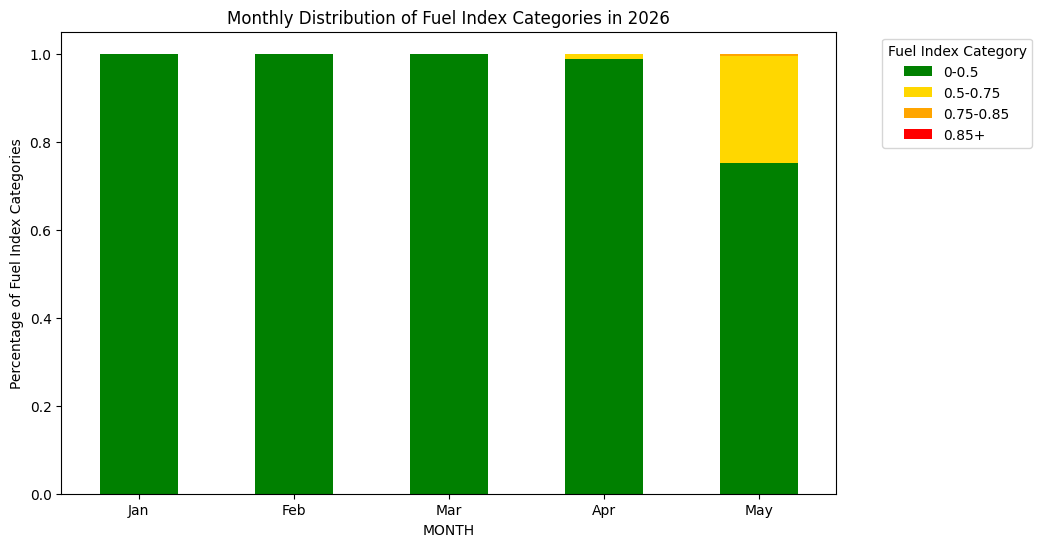

In [50]:
# plot a stacked bar chart to show the percentage of each FUEL_INDEX_CATEGORY in each month
pivot_table = fuel_data_monthly.pivot(index='MONTH', columns='FUEL_INDEX_CATEGORY', values='PERCENTAGE')
# create a figure to plot
fig, ax = plt.subplots(figsize=(10, 6))
# plot the stacked bar chart, make 0-0.5 category in green, 0.5-0.75 in gold, 0.75-0.85 in orange, 0.85+ in red
color_mapping = {
    '0-0.5': 'green',
    '0.5-0.75': 'gold',
    '0.75-0.85': 'orange',
    '0.85+': 'red'
}
ax = pivot_table.plot(kind='bar', stacked=True, ax=ax, color=[color_mapping.get(x, 'gray') for x in pivot_table.columns])
# set the x-axis label, change the x-ticks to show month names
ax.set_xticks(range(len(fuel_data_monthly['MONTH'].unique())))
# get month names from month numbers, but month name as 3 letter abbreviation
month_names = fuel_data_monthly['MONTH'].unique()
month_names = [pd.to_datetime(str(month), format='%m').strftime('%b') for month in month_names]
ax.set_xticklabels(month_names, rotation=0)
# set the y-axis label
ax.set_ylabel('Percentage of Fuel Index Categories')
# set the title
ax.set_title('Monthly Distribution of Fuel Index Categories in 2026')
# add legend outside the plot
ax.legend(title='Fuel Index Category', bbox_to_anchor=(1.05, 1), loc='upper left')